# Time Series Practice 2

**Dữ liệu:** Monthly Retail Sales (`a10.csv`), từ 1991-07 đến 2008-06.

In [136]:
import sys

src_path = r"D:\TimeSeries_Data\total_practice\Practice_2\src"

if src_path not in sys.path:
    sys.path.insert(0, src_path)

print(sys.path[:5])
from practice_2.data.time_series_data import load_monthly_retail_sales, chronological_split
from practice_2.visualization.plots import save_series_plot
from practice_2.analysis.stationarity import log_first_difference


['D:\\TimeSeries_Data\\total_practice\\Practice_2\\src', 'c:\\Users\\PC\\AppData\\Local\\Programs\\Python\\Python311\\python311.zip', 'c:\\Users\\PC\\AppData\\Local\\Programs\\Python\\Python311\\DLLs', 'c:\\Users\\PC\\AppData\\Local\\Programs\\Python\\Python311\\Lib', 'c:\\Users\\PC\\AppData\\Local\\Programs\\Python\\Python311']


In [137]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
from practice_2.data.time_series_data import load_monthly_retail_sales, chronological_split
from practice_2.visualization.plots import save_series_plot

PROJECT_ROOT = next((p for p in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent] if (p / 'datasets' / 'raw' / 'a10.csv').is_file()), None)
if PROJECT_ROOT is None: raise FileNotFoundError('Không tìm thấy Practice 2 root')
RAW_PATH = PROJECT_ROOT / 'datasets' / 'raw' / 'a10.csv'
FIGURES_DIR = PROJECT_ROOT / 'outputs' / 'figures'
RESULTS_DIR = PROJECT_ROOT / 'outputs' / 'results'
FIGURES_DIR.mkdir(parents=True, exist_ok=True); RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# Exercise 1 — Khám phá dữ liệu (EDA)
<a id="exercise-1"></a>

### Kiểm tra dữ liệu trước

In [138]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df = pd.read_csv(RAW_PATH, parse_dates=["date"])

# Sắp xếp theo thời gian và đưa date thành index
df = df.sort_values("date").set_index("date")

# Kiểm tra thông tin dữ liệu
print(df.info())
print("\n5 dòng đầu:")
print(df.head())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 204 entries, 1991-07-01 to 2008-06-01
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   value   204 non-null    float64
dtypes: float64(1)
memory usage: 3.2 KB
None

5 dòng đầu:
               value
date                
1991-07-01  3.526591
1991-08-01  3.180891
1991-09-01  3.252221
1991-10-01  3.611003
1991-11-01  3.565869


In [139]:
print("\nThống kê mô tả:")
print(df["value"].describe())

# Kiểm định dữ liệu
expected_index = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq="MS"
)

validation = pd.DataFrame({
    "metric": [
        "rows",
        "start",
        "end",
        "index_type",
        "frequency",
        "missing_values",
        "duplicate_timestamps",
        "missing_intervals",
        "chronological"
    ],
    "value": [
        len(df),
        df.index.min(),
        df.index.max(),
        type(df.index).__name__,
        df.index.freqstr,
        int(df["value"].isna().sum()),
        int(df.index.has_duplicates),
        len(expected_index.difference(df.index)),
        df.index.is_monotonic_increasing
    ]
})

display(validation)


Thống kê mô tả:
count    204.000000
mean      10.694430
std        5.956998
min        2.814520
25%        5.844095
50%        9.319345
75%       14.289964
max       29.665356
Name: value, dtype: float64


,metric,value
0,rows,204
1,start,1991-07-01 00:00:00
2,end,2008-06-01 00:00:00
3,index_type,DatetimeIndex
4,frequency,None
5,missing_values,0
6,duplicate_timestamps,0
7,missing_intervals,0
8,chronological,True


### Chia train/test theo thời gian

In [140]:
expected_index = pd.date_range(series.index.min(), series.index.max(), freq='MS')
validation = pd.DataFrame({'metric':['rows','start','end','index_type','frequency','missing_values','duplicate_timestamps','missing_intervals','chronological'],'value':[len(series),series.index.min(),series.index.max(),type(series.index).__name__,series.index.freqstr,int(series.isna().sum()),int(series.index.has_duplicates),len(expected_index.difference(series.index)),series.index.is_monotonic_increasing]})
boundary = pd.DataFrame({'split':['train','test'],'start':[train_series.index.min(),test_series.index.min()],'end':[train_series.index.max(),test_series.index.max()],'observations':[len(train_series),len(test_series)],'forecast_horizon':[None,len(test_series)]})
validation.to_csv(RESULTS_DIR / 'dataset_validation.csv', index=False); boundary.to_csv(RESULTS_DIR / 'train_test_boundary.csv', index=False)
display(boundary)


,split,start,end,observations,forecast_horizon
0,train,1991-07-01,2005-01-01,163,NaN
1,test,2005-02-01,2008-06-01,41,41.0


In [141]:

import numpy as np
import pandas as pd


series = df["value"].copy()
series = pd.to_numeric(series, errors="coerce")
series = series.dropna()

mean_value = series.mean()
median_value = series.median()
std_value = series.std()
variance_value = series.var()

cv = (
    std_value / mean_value * 100
    if mean_value != 0 else np.nan
)

skewness = series.skew()
kurtosis = series.kurt()

start_value = float(series.iloc[0])
end_value = float(series.iloc[-1])

absolute_change = end_value - start_value

percentage_change = (
    (end_value / start_value - 1) * 100
    if start_value != 0 else np.nan
)

# CAGR: tốc độ tăng trưởng kép bình quân năm
if isinstance(series.index, pd.DatetimeIndex):
    elapsed_years = (
        (series.index[-1] - series.index[0]).days / 365.2425
    )
else:
    elapsed_years = np.nan

cagr = (
    ((end_value / start_value) ** (1 / elapsed_years) - 1) * 100
    if pd.notna(elapsed_years)
    and elapsed_years > 0
    and start_value > 0
    and end_value > 0
    else np.nan
)

# Mức thay đổi theo tháng
monthly_change = series.diff().dropna()
monthly_pct_change = series.pct_change().dropna() * 100

max_monthly_increase = monthly_change.max()
max_monthly_decrease = monthly_change.min()

max_monthly_growth = monthly_pct_change.max()
max_monthly_decline = monthly_pct_change.min()

# Tự tương quan
autocorr_1 = series.autocorr(lag=1)
autocorr_12 = (
    series.autocorr(lag=12)
    if len(series) > 12 else np.nan
)

# Phát hiện ngoại lệ bằng quy tắc IQR
q1, q3 = series.quantile([0.25, 0.75])
iqr = q3 - q1

potential_outliers = series[
    (series < q1 - 1.5 * iqr) |
    (series > q3 + 1.5 * iqr)
]

outlier_count = len(potential_outliers)
outlier_percentage = outlier_count / len(series) * 100

# Tổng hợp các chỉ số
additional_metrics = pd.DataFrame({
    "metric": [
        "median",
        "variance",
        "coefficient_of_variation_pct",
        "skewness",
        "kurtosis",
        "absolute_change",
        "percentage_change_pct",
        "cagr_pct",
        "max_monthly_increase",
        "max_monthly_decrease",
        "max_monthly_growth_pct",
        "max_monthly_decline_pct",
        "autocorrelation_lag_1",
        "autocorrelation_lag_12",
        "potential_outlier_count",
        "potential_outlier_percentage"
    ],
    "value": [
        median_value,
        variance_value,
        cv,
        skewness,
        kurtosis,
        absolute_change,
        percentage_change,
        cagr,
        max_monthly_increase,
        max_monthly_decrease,
        max_monthly_growth,
        max_monthly_decline,
        autocorr_1,
        autocorr_12,
        outlier_count,
        outlier_percentage
    ]
})

display(additional_metrics)


,metric,value
0,median,9.319345
1,variance,35.485823
2,coefficient_of_variation_pct,55.701875
3,skewness,0.843794
4,kurtosis,0.028921
5,absolute_change,15.905149
6,percentage_change_pct,451.006340
7,cagr_pct,10.612165
8,max_monthly_increase,4.842732
9,max_monthly_decrease,-11.274514


### Biểu đồ chuỗi thời gian

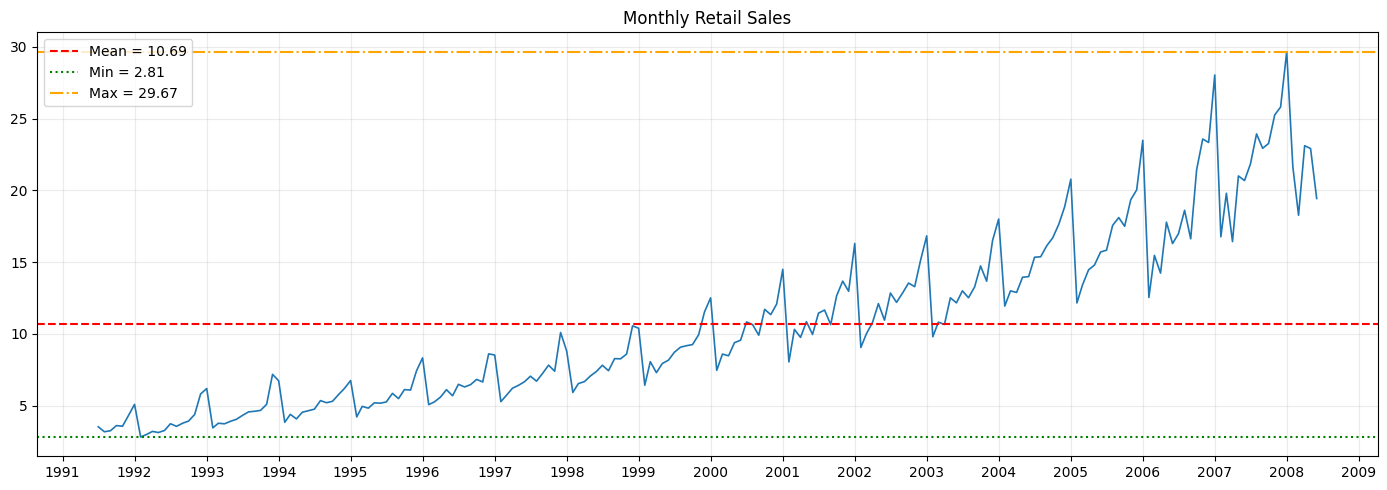

In [142]:

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Đọc dữ liệu
df = pd.read_csv(
    RAW_PATH,
    parse_dates=["date"]
)

# Vẽ biểu đồ
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    df["date"],
    df["value"],
    linewidth=1.2
)

# Tiêu đề
ax.set_title("Monthly Retail Sales")

# Tính giá trị Mean, Min, Max
mean_value = df["value"].mean()
min_value = df["value"].min()
max_value = df["value"].max()
# Đường Mean
ax.axhline(
    y=mean_value,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Mean = {mean_value:.2f}"
)
# Đường Min
ax.axhline(
    y=min_value,
    color="green",
    linestyle=":",
    linewidth=1.5,
    label=f"Min = {min_value:.2f}"
)
# Đường Max
ax.axhline(
    y=max_value,
    color="orange",
    linestyle="-.",
    linewidth=1.5,
    label=f"Max = {max_value:.2f}"
)

# Hiển thị năm trên trục X, cách nhau YearLocator
ax.xaxis.set_major_locator(mdates.YearLocator(1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.grid(True, alpha=0.25)
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()


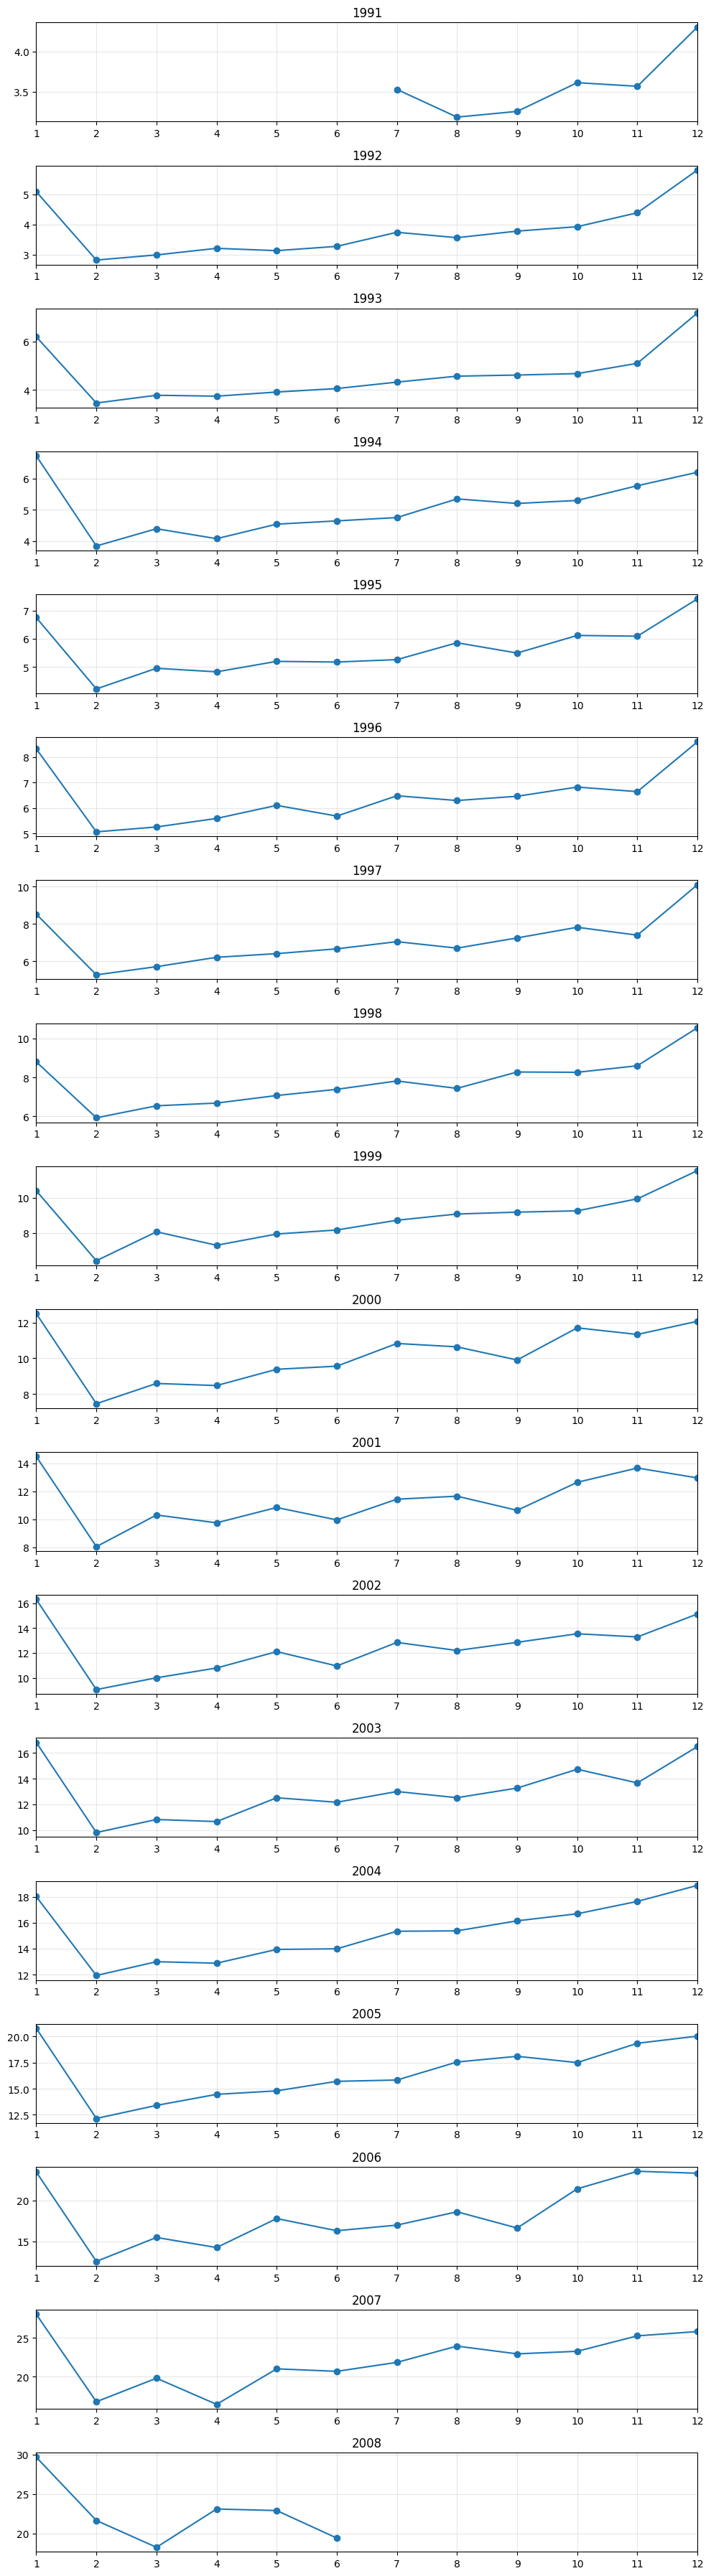

In [143]:

import pandas as pd
from matplotlib import pyplot as plt

df = pd.read_csv(RAW_PATH, header=0, parse_dates=["date"])

df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month

years = df.pivot(index="month", columns="year", values="value")

fig, axes = plt.subplots(
    nrows=len(years.columns),
    ncols=1,
    figsize=(10, 2 * len(years.columns)),
    squeeze=False
)

for ax, year in zip(axes[:, 0], years.columns):
    ax.plot(years.index, years[year], marker="o")
    ax.set_title(str(year))
    ax.set_xticks(range(1, 13))
    ax.set_xlim(1, 12)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [144]:
series

date
1991-07-01     3.526591
1991-08-01     3.180891
1991-09-01     3.252221
1991-10-01     3.611003
1991-11-01     3.565869
                ...    
2008-02-01    21.654285
2008-03-01    18.264945
2008-04-01    23.107677
2008-05-01    22.912510
2008-06-01    19.431740
Name: value, Length: 204, dtype: float64

In [145]:
monthly_data[10]

array([ 3.565869  ,  4.38653092,  5.09384145,  5.77374216,  6.08847284,
        6.64907826,  7.39810106,  8.59615575,  9.93313643, 11.34015074,
       13.67446631, 13.28764   , 13.66938174, 17.636728  , 19.347265  ,
       23.575517  , 25.25003022])

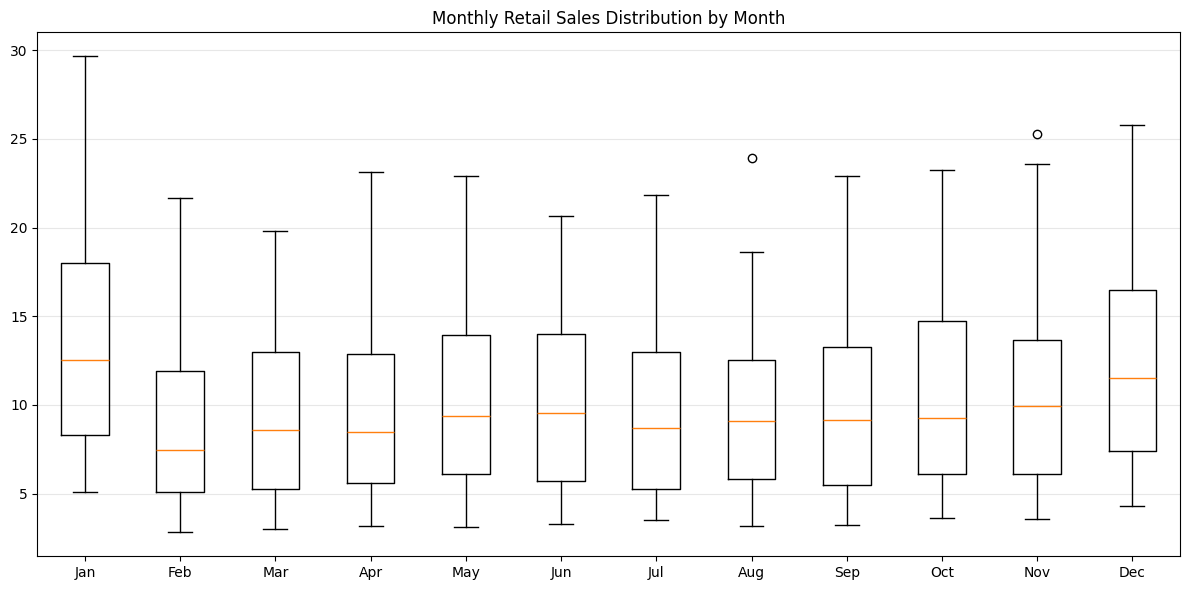

In [146]:
from pandas import read_csv
from matplotlib import pyplot

# Đọc dữ liệu
series = read_csv(
    RAW_PATH,
    header=0,
    parse_dates=["date"],
    index_col="date"
)["value"]

monthly_data = [
    series[series.index.month == month].dropna().values
    for month in range(1, 13)
]

# Vẽ Boxplot
pyplot.figure(figsize=(12, 6))

pyplot.boxplot(
    monthly_data,
    tick_labels=[
        "Jan", "Feb", "Mar", "Apr", "May", "Jun",
        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
    ]
)

pyplot.title("Monthly Retail Sales Distribution by Month")
pyplot.grid(axis="y", alpha=0.3)

pyplot.tight_layout()
pyplot.show()


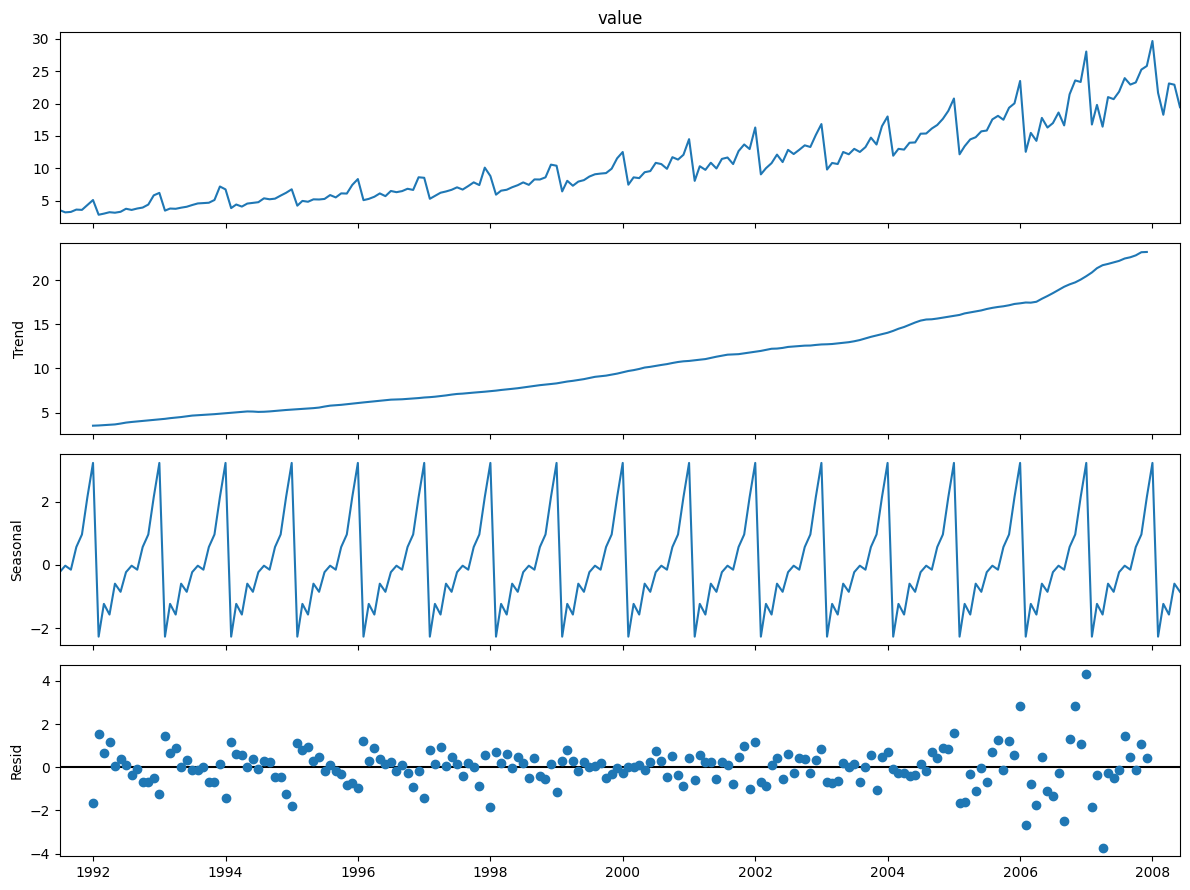

In [147]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

result = seasonal_decompose(
    series,
    model="additive",
    period=12
)

# 6. Vẽ các thành phần
fig = result.plot()
fig.set_size_inches(12, 9)
plt.tight_layout()
plt.show()


# Exercise 2 — Kiểm định ADF trên chuỗi gốc
<a id="exercise-2"></a>

### 1. Kiểm định ADF

**H₀:** chuỗi có unit root. Ngưỡng kiểm định: `α = 0.05`.

### 2. Kết quả trên chuỗi train gốc

Input: 163 quan sát train; 41 quan sát test không được sử dụng.

In [148]:

import pandas as pd
from statsmodels.tsa.stattools import adfuller

# Bước 1: Chuẩn bị chuỗi gốc
df = pd.read_csv(RAW_PATH, parse_dates=["date"])
df = df.sort_values("date").set_index("date")
series = pd.to_numeric(df["value"], errors="coerce")
series = series.asfreq("MS")

# Bước 2: Thực hiện kiểm định ADF trên chuỗi gốc
adf_result = adfuller(
    series,
    regression="ct",
    autolag="AIC"
)

# Bước 3: Lấy kết quả
adf_statistic = adf_result[0]
p_value = adf_result[1]
critical_value_5 = adf_result[4]["5%"]

print("ADF Statistic:", adf_statistic)
print("p-value:", p_value)
print("Critical Value (5%):", critical_value_5)

# Bước 4: Kết luận ở mức ý nghĩa 5%
if p_value < 0.05:
    print("Kết luận: Bác bỏ H0.")
else:
    print("Kết luận: Chưa đủ bằng chứng bác bỏ H0.")


ADF Statistic: 1.0944081802980727
p-value: 1.0
Critical Value (5%): -3.4341056787874553
Kết luận: Chưa đủ bằng chứng bác bỏ H0.


C:\Users\PC\AppData\Local\Temp\ipykernel_9940\815869727.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(


### 3. Kết luận E02

Chuỗi không dừng (không bác bỏ giả thuyết H₀ về tồn tại nghiệm đơn vị), do p-value xấp xỉ 1.0 > 0.05 và ADF Statistic = 1.094 > Critical Value (5%) = -3.434. Cần thực hiện sai phân hoặc các bước xử lý để đưa chuỗi về dừng trước khi xây dựng mô hình.

# Exercise 3 — Sai phân và kiểm định lại
<a id="exercise-3"></a>

### Sai phân bậc 1

In [155]:
series = df['value']

series_diff = series.diff().dropna()

print(series_diff)

date
1991-08-01   -0.345700
1991-09-01    0.071330
1991-10-01    0.358782
1991-11-01   -0.045134
1991-12-01    0.740502
                ...   
2008-02-01   -8.011071
2008-03-01   -3.389340
2008-04-01    4.842732
2008-05-01   -0.195167
2008-06-01   -3.480770
Name: value, Length: 203, dtype: float64


### Đồ thị chuỗi sau khi sai phân bậc 1

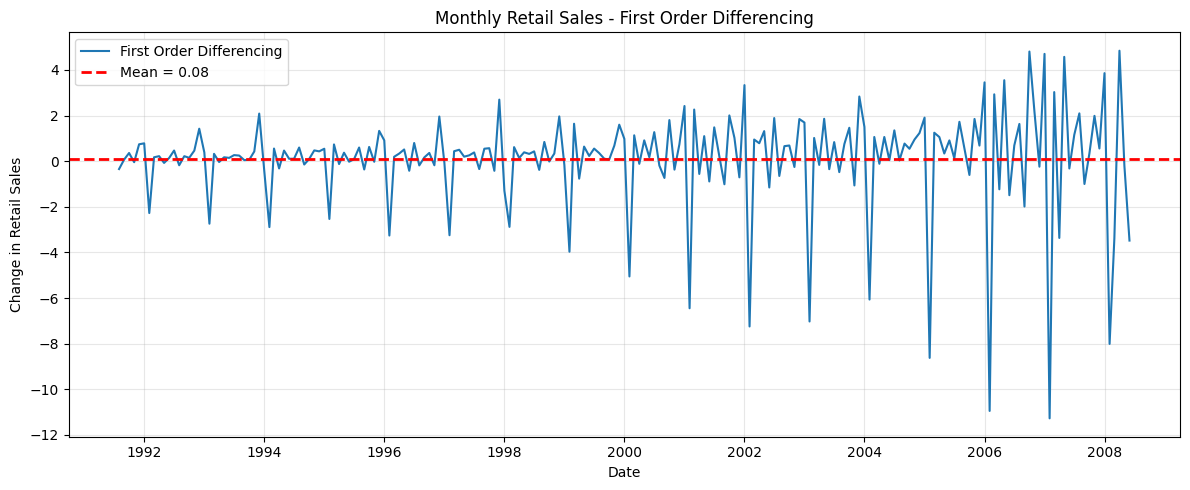

In [152]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Vẽ chuỗi sau sai phân bậc 1
plt.plot(
    series_diff.index,
    series_diff.values,
    label="First Order Differencing"
)

# Tính giá trị trung bình
mean_value = series_diff.mean()

# Vẽ đường trung bình
plt.axhline(
    y=mean_value,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_value:.2f}"
)

plt.title("Monthly Retail Sales - First Order Differencing")
plt.xlabel("Date")
plt.ylabel("Change in Retail Sales")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Kiểm định ADF sau sai phân bậc 1

In [157]:
from statsmodels.tsa.stattools import adfuller

# Kiểm định ADF trên chuỗi sau sai phân
adf_result_diff = adfuller(
    series_diff,
    regression="c",
    autolag="AIC"
)

print("ADF Statistic:", adf_result_diff[0])
print("p-value:", adf_result_diff[1])
print("Critical Values:", adf_result_diff[4]["5%"])

if adf_result_diff[1] < 0.05:
    print("Bác bỏ H0: Có bằng chứng chuỗi sau sai phân là chuỗi dừng.")
else:
    print("Chưa đủ bằng chứng bác bỏ H0: Cần kiểm tra thêm.")

ADF Statistic: -2.495172147449788
p-value: 0.11665341686467584
Critical Values: -2.877123351472649
Chưa đủ bằng chứng bác bỏ H0: Cần kiểm tra thêm.


C:\Users\PC\AppData\Local\Temp\ipykernel_9940\2750120097.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result_diff = adfuller(


Vì \(0.1167 > 0.05\), ta chưa bác bỏ giả thuyết \(H_0\). Nghĩa là chưa đủ bằng chứng thống kê để kết luận chuỗi sau sai phân bậc 1 đã dừng và ADF Statistic là \(-2.4952\), lớn hơn Critical Value \(-2.8771\) (ít âm hơn), nên kết quả cũng cho cùng kết luận ở mức ý nghĩa 5%.

### Sai phân bậc 2

In [158]:
# Sai phân bậc 2 từ chuỗi đã sai phân bậc 1
series_diff2 = series_diff.diff().dropna()

# Kiểm tra dữ liệu
print(series_diff2.head())
print("Số quan sát sau sai phân bậc 2:", len(series_diff2))

date
1991-09-01    0.417030
1991-10-01    0.287452
1991-11-01   -0.403916
1991-12-01    0.785636
1992-01-01    0.041462
Name: value, dtype: float64
Số quan sát sau sai phân bậc 2: 202


### Sai phân bậc 2

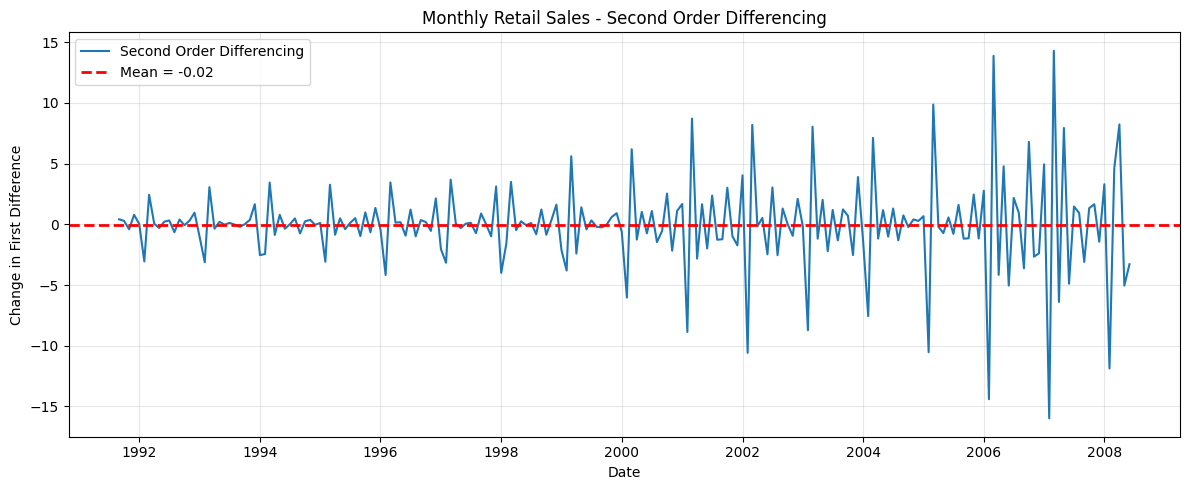

In [159]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    series_diff2.index,
    series_diff2.values,
    label="Second Order Differencing"
)

mean_value2 = series_diff2.mean()

plt.axhline(
    y=mean_value2,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_value2:.2f}"
)

plt.title("Monthly Retail Sales - Second Order Differencing")
plt.xlabel("Date")
plt.ylabel("Change in First Difference")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Kiểm định ADF sau sai phân bậc 2

In [162]:
from statsmodels.tsa.stattools import adfuller

adf_result_diff2 = adfuller(
    series_diff2,
    regression="c",
    autolag="AIC"
)

print("ADF Statistic:", adf_result_diff2[0])
print("p-value:", adf_result_diff2[1])
print("Critical Values:", adf_result_diff2[4]["5%"])

if adf_result_diff2[1] < 0.05:
    print("Bác bỏ H0: Có bằng chứng chuỗi sau sai phân bậc 2 là chuỗi dừng.")
else:
    print("Chưa đủ bằng chứng bác bỏ H0: Cần xem xét thêm.")

ADF Statistic: -10.292304706517312
p-value: 3.5439163585295715e-18
Critical Values: -2.877123351472649
Bác bỏ H0: Có bằng chứng chuỗi sau sai phân bậc 2 là chuỗi dừng.


C:\Users\PC\AppData\Local\Temp\ipykernel_9940\2471976458.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result_diff2 = adfuller(


### 3. KẾT LUẬN
**Sau sai phân, chuỗi đã dừng chưa?**
Có. Sau sai phân bậc 2, kiểm định ADF cho kết quả p-value  3.5439163585295715e-18 < 0.05, nên bác bỏ H_0. Có bằng chứng thống kê cho thấy chuỗi sau sai phân là chuỗi dừng theo kiểm định ADF.

**Giá trị d trong ARIMA là bao nhiêu?**
Theo kết quả hiện tại, d= 2, vì chuỗi cần sai phân bậc 2 để đạt tính dừng theo kiểm định ADF. Tuy nhiên, nên kiểm tra thêm khả năng sai phân quá mức và yếu tố mùa vụ trước khi chốt mô hình cuối cùng.

# Exercise 4: Phân tích ACF & PACF

### Vẽ biểu đồ ACF và PACF của chuỗi đã dừng

### Biểu đồ ACF

<Figure size 1200x500 with 0 Axes>

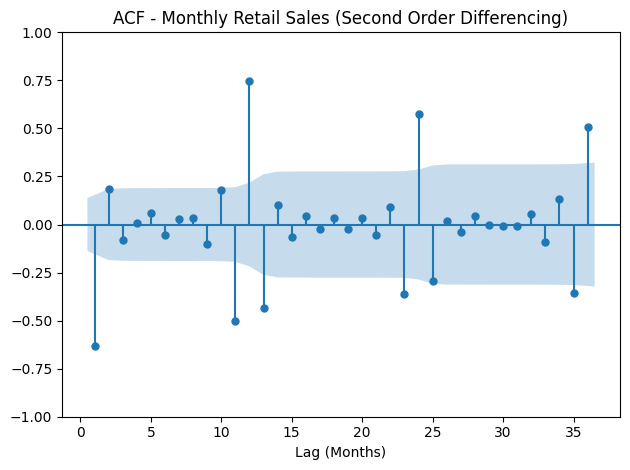

In [163]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plot_acf(series_diff2, lags=36, zero=False)

plt.title("ACF - Monthly Retail Sales (Second Order Differencing)")
plt.xlabel("Lag (Months)")
plt.tight_layout()
plt.show()


Lag 1 có tương quan âm mạnh, có thể phản ánh ảnh hưởng của sai phân hoặc cấu trúc MA.
Các lag 12, 24, 36 nổi bật cách nhau 12 tháng, cho thấy dấu hiệu mùa vụ chu kỳ 12 tháng rất rõ ràng. Vì vậy, dữ liệu này có thể phù hợp với việc xem xét mô hình mùa vụ SARIMA, thay vì chỉ dùng ARIMA thông thường.

#### Biểu đồ PACF

<Figure size 1200x500 with 0 Axes>

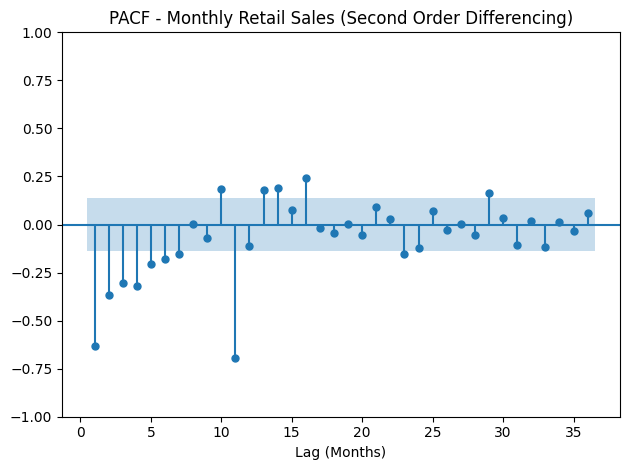

In [164]:
from statsmodels.graphics.tsaplots import plot_pacf
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plot_pacf(series_diff2, lags=36, zero=False, method="ywm")

plt.title("PACF - Monthly Retail Sales (Second Order Differencing)")
plt.xlabel("Lag (Months)")
plt.tight_layout()
plt.show()


PACF không cắt cụt rõ ràng ngay sau một lag mà có nhiều cột nổi bật. Điều này khiến việc xác định \(p\) chỉ bằng cách đếm cột trở nên khó khăn. Đặc biệt, lag 11 và các lag gần 12 có thể liên quan đến cấu trúc mùa vụ hoặc việc sai phân bậc 2 đã làm thay đổi cấu trúc tương quan.

### Kết luận E04
##### **Đề xuất (p, d, q)**
##### Mô hình: ARIMA(1,2,0) | p: 1 | d: 2 | q: 0 | Mục đích: Thử cấu trúc AR bậc thấp
##### Mô hình: ARIMA(0,2,1) | p: 0 | d: 2 | q: 1 | Mục đích: Thử cấu trúc MA bậc thấp
##### Mô hình: ARIMA(1,2,1) | p: 1 | d: 2 | q: 1 | Mục đích: Kết hợp AR và MA
##### Đây chỉ là các đề xuất ban đầu để xem xét ở E05, không phải kết luận về mô hình cuối cùng. Cần đối chiếu với ACF/PACF thực tế của chuỗi phân tích trước khi chọn candidate.

# Exercise 5: Thiết lập ARIMA / SARIMA – Dự đoán – Đánh giá

### Chia dữ liệu train 80%, test 20%

In [ ]:

# Chia dữ liệu theo thứ tự thời gian
n_train = int(len(series) * 0.8)

train = series.iloc[:n_train]
test = series.iloc[n_train:]

print("Số quan sát train:", len(train))
print("Số quan sát test:", len(test))
print("Thời gian train:", train.index.min(), "->", train.index.max())
print("Thời gian test:", test.index.min(), "->", test.index.max())

Số quan sát train: 163
Số quan sát test: 41
Thời gian train: 1991-07-01 00:00:00 -> 2005-01-01 00:00:00
Thời gian test: 2005-02-01 00:00:00 -> 2008-06-01 00:00:00


### Thiết lập và huấn luyện mô hình

In [170]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

#### Mô hình 1: ARIMA(1,2,0)

In [171]:
model_arima1 = ARIMA(
    train,
    order=(1, 2, 0)
)
result_arima1 = model_arima1.fit()

#### Mô hình 2: ARIMA(0,2,1)

In [172]:
model_arima2 = ARIMA(
    train,
    order=(0, 2, 1)
)
result_arima2 = model_arima2.fit()

#### Mô hình 3: SARIMA(0,1,1)(0,1,1,12)

In [173]:
model_sarima = SARIMAX(
    train,
    order=(0, 1, 1),
    seasonal_order=(0, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)
result_sarima = model_sarima.fit(disp=False)

#### So sánh AIC và BIC

In [ ]:
comparison = pd.DataFrame({
    "Model": [
        "ARIMA(1,2,0)",
        "ARIMA(0,2,1)",
        "SARIMA(0,1,1)(0,1,1,12)"
    ],
    "AIC": [
        result_arima1.aic,
        result_arima2.aic,
        result_sarima.aic
    ],
    "BIC": [
        result_arima1.bic,
        result_arima2.bic,
        result_sarima.bic
    ]
})

print(comparison.sort_values("AIC"))


                     Model         AIC         BIC
2  SARIMA(0,1,1)(0,1,1,12)  233.851680  242.589645
1             ARIMA(0,2,1)  616.346783  622.509591
0             ARIMA(1,2,0)  697.974723  704.137532


In [175]:
results = {
    "ARIMA(1,2,0)": result_arima1,
    "ARIMA(0,2,1)": result_arima2,
    "SARIMA(0,1,1)(0,1,1,12)": result_sarima
}

best_name = min(results, key=lambda name: results[name].aic)
best_result = results[best_name]

print("Mô hình có AIC thấp nhất:", best_name)
print("AIC:", best_result.aic)
print("BIC:", best_result.bic)

# Phần dư của mô hình
residuals = pd.Series(
    best_result.resid,
    index=train.index
).dropna()

print("Trung bình phần dư:", residuals.mean())


Mô hình có AIC thấp nhất: SARIMA(0,1,1)(0,1,1,12)
AIC: 233.8516798807666
BIC: 242.58964453797475
Trung bình phần dư: 0.06552112920879051


Trong các mô hình được ước lượng trên cùng dữ liệu, AIC/BIC thấp hơn thường là dấu hiệu tốt hơn. Tuy nhiên, đừng chọn mô hình chỉ dựa vào hai chỉ số này; cần kiểm tra phần dư và dự báo trên tập test.

#### Vẽ phần dư theo thời gian và ACF của phần dư

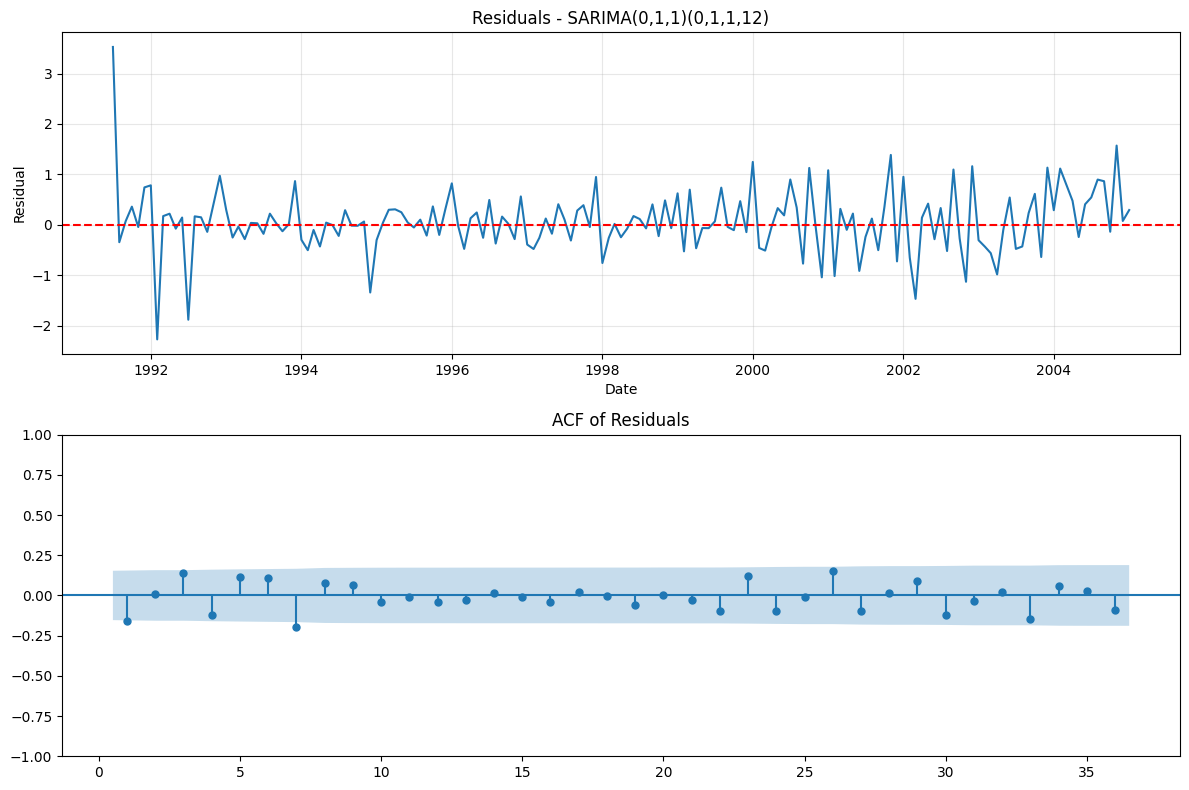

In [176]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# Residuals theo thời gian
axes[0].plot(residuals.index, residuals.values)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title(f"Residuals - {best_name}")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Residual")
axes[0].grid(True, alpha=0.3)

# ACF của phần dư
plot_acf(residuals, lags=36, zero=False, ax=axes[1])
axes[1].set_title("ACF of Residuals")

plt.tight_layout()
plt.show()


Phần dư chủ yếu dao động quanh 0 và ACF phần dư phần lớn nằm trong vùng tin cậy.

#### Kiểm tra bằng Ljung–Box

In [177]:
from statsmodels.stats.diagnostic import acorr_ljungbox

print(acorr_ljungbox(
    residuals,
    lags=[12, 24],
    return_df=True
))


      lb_stat  lb_pvalue
12  22.867776   0.028870
24  30.407572   0.171608


Kiểm định Ljung–Box cho kết quả p-value tại lag 12 bằng 0.0289, nhỏ hơn mức ý nghĩa 5%, cho thấy phần dư vẫn còn dấu hiệu tự tương quan. Tại lag 24, p-value bằng 0.1716 nên chưa có đủ bằng chứng bác bỏ giả thuyết không có tự tương quan đến độ trễ này. Vì vậy, mô hình SARIMA cần được đánh giá thêm bằng dự báo trên tập kiểm tra và các chỉ số MAE, RMSE, MAPE.

#### Dự đoán trên tập test

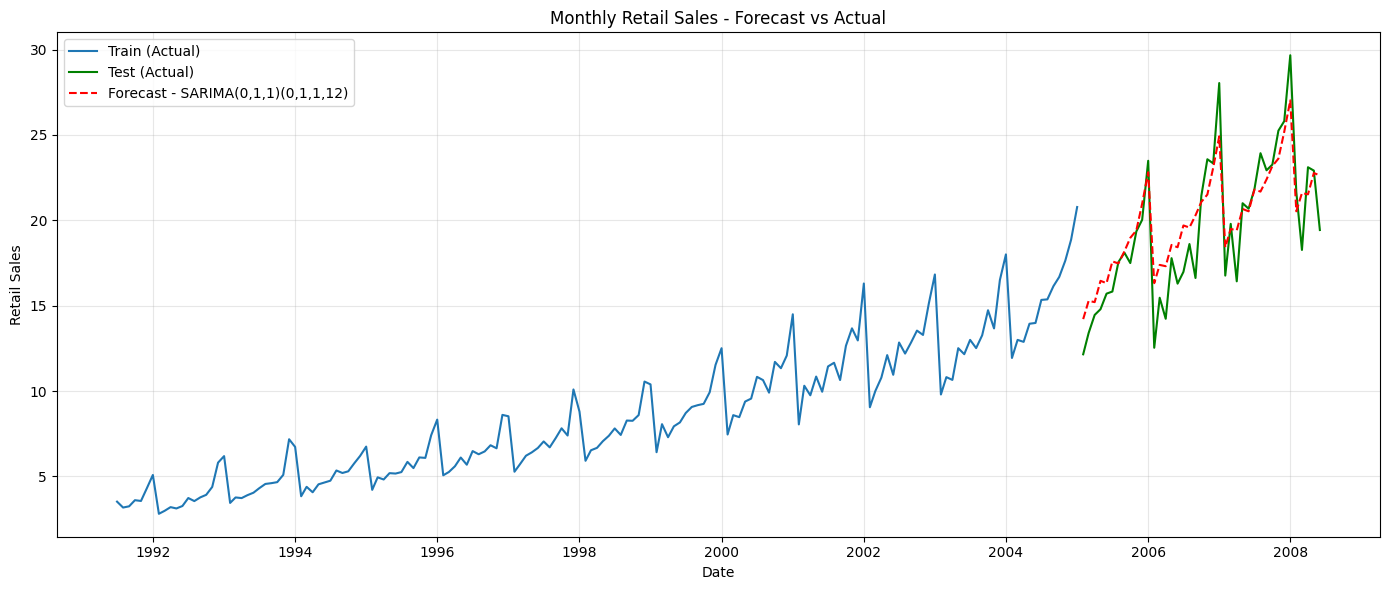

In [178]:
import numpy as np
import matplotlib.pyplot as plt

# Dự báo cho toàn bộ giai đoạn test
forecasts = {}

for name, result in results.items():
    forecast_values = result.forecast(steps=len(test))
    forecasts[name] = np.asarray(forecast_values)

# Lấy dự báo từ mô hình có AIC thấp nhất
best_forecast = forecasts[best_name]

plt.figure(figsize=(14, 6))

plt.plot(
    train.index, train.values,
    label="Train (Actual)"
)
plt.plot(
    test.index, test.values,
    label="Test (Actual)",
    color="green"
)
plt.plot(
    test.index, best_forecast,
    label=f"Forecast - {best_name}",
    color="red",
    linestyle="--"
)

plt.title("Monthly Retail Sales - Forecast vs Actual")
plt.xlabel("Date")
plt.ylabel("Retail Sales")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


#### Đánh giá mô hình bằng MAE, RMSE, MAPE

In [179]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

evaluation = []

y_true = test.to_numpy()

for name, y_pred in forecasts.items():
    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    # MAPE: chỉ phù hợp khi giá trị thực tế khác 0
    mape = np.mean(
        np.abs((y_true - y_pred) / y_true)
    ) * 100

    evaluation.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    })

evaluation_df = pd.DataFrame(evaluation)
print(evaluation_df.sort_values("RMSE"))


                     Model        MAE       RMSE    MAPE (%)
2  SARIMA(0,1,1)(0,1,1,12)   1.451525   1.842603    8.211587
1             ARIMA(0,2,1)   4.181580   4.884780   24.903702
0             ARIMA(1,2,0)  36.006643  39.855773  181.816705


| Chỉ số  | Ý nghĩa   | Tốt hơn khi               |
| ---     | ---       | ---                       |
| **MAE** | Sai số tuyệt đối trung bình           | Thấp hơn
| **RMSE** | Phạt mạnh hơn các sai số lớn         | Thấp hơn
| **MAPE** | Sai số phần trăm tuyệt đối trung bình| Thấp hơn


Qua quá trình so sánh ba mô hình trên tập kiểm tra, SARIMA(0,1,1)(0,1,1,12) đạt kết quả tốt nhất với MAE = 1.4515, RMSE = 1.8426 và MAPE = 8.21%. Kết quả cho thấy mô hình SARIMA dự báo doanh số bán lẻ tốt hơn hai mô hình ARIMA được thử nghiệm, có thể nhờ khả năng mô hình hóa tính mùa vụ chu kỳ 12 tháng.

### Kết luận E05
1. Chia dữ liệu: Chia chuỗi Monthly Retail Sales thành tập train (80%) và test (20%), giữ nguyên thứ tự thời gian, không shuffle.

2. Thiết lập mô hình: Xây dựng và huấn luyện hai mô hình ARIMA(1,2,0), ARIMA(0,2,1) và một mô hình SARIMA(0,1,1)(0,1,1,12). Ghi nhận AIC và BIC để so sánh độ phù hợp của các mô hình.

3. Chẩn đoán phần dư: Vẽ biểu đồ phần dư theo thời gian và ACF phần dư. Phần dư chủ yếu dao động quanh 0, nhưng kiểm định Ljung–Box cho p-value tại lag 12 là 0.0289, cho thấy vẫn còn dấu hiệu tự tương quan.

4. Dự đoán: Sử dụng các mô hình đã huấn luyện để dự báo doanh số trên tập test và so sánh giá trị dự báo với dữ liệu thực tế.

5. Đánh giá mô hình: SARIMA(0,1,1)(0,1,1,12) cho kết quả tốt nhất trong ba mô hình đã thử nghiệm, với MAE = 1.4515, RMSE = 1.8426 và MAPE = 8.21%.

Kết luận chung: Mô hình SARIMA cho khả năng dự báo tốt hơn hai mô hình ARIMA được thử nghiệm, phù hợp với đặc điểm mùa vụ 12 tháng của dữ liệu. Tuy nhiên, do phần dư vẫn còn dấu hiệu tự tương quan, cần cân nhắc cải thiện mô hình trước khi khẳng định mô hình đã phù hợp hoàn toàn.